In [1]:
import json
import os

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

In [2]:
with open('../results/eval_attn_logit_std_410m.jsonl') as f:
    rows = [json.loads(line) for line in f]

rows.sort(key=lambda r: int(r['revision'].replace('step', '')))

steps = np.array([int(r['revision'].replace('step', '')) for r in rows])
# attn_std: (n_steps, n_layers, num_heads)
attn_std = np.array([r['attn_logit_std'] for r in rows])
attn_entropy = np.array([r['attn_entropy'] for r in rows])

n_layers, num_heads = attn_std.shape[1], attn_std.shape[2]

# Dynamic time tau
def lr_scheduler(step, total_steps=143000):
    if step < total_steps * 0.01:
        return step / (total_steps * 0.01)
    progress = (step - total_steps * 0.01) / (total_steps * 0.99)
    return 0.5 * (1.0 + np.cos(np.pi * progress)) * 0.9 + 0.1

cache_path = '../cache/lrs_cache.npy'
if os.path.exists(cache_path):
    lrs = np.load(cache_path)
else:
    lrs = np.array([lr_scheduler(s) for s in range(1, 143001)])
    np.save(cache_path, lrs)

cumsum = np.cumsum(lrs)
tau = cumsum[steps - 1]

print(f'Steps: {steps}')
print(f'attn_std shape: {attn_std.shape}  (n_steps, n_layers, num_heads)')
print(f'attn_entropy shape: {attn_entropy.shape}  (n_steps, n_layers, num_heads)')

Steps: [   128    256    512   1000   2000   3000   6000  12000  16000  32000
  48000  79000 143000]
attn_std shape: (13, 24, 16)  (n_steps, n_layers, num_heads)
attn_entropy shape: (13, 24, 16)  (n_steps, n_layers, num_heads)


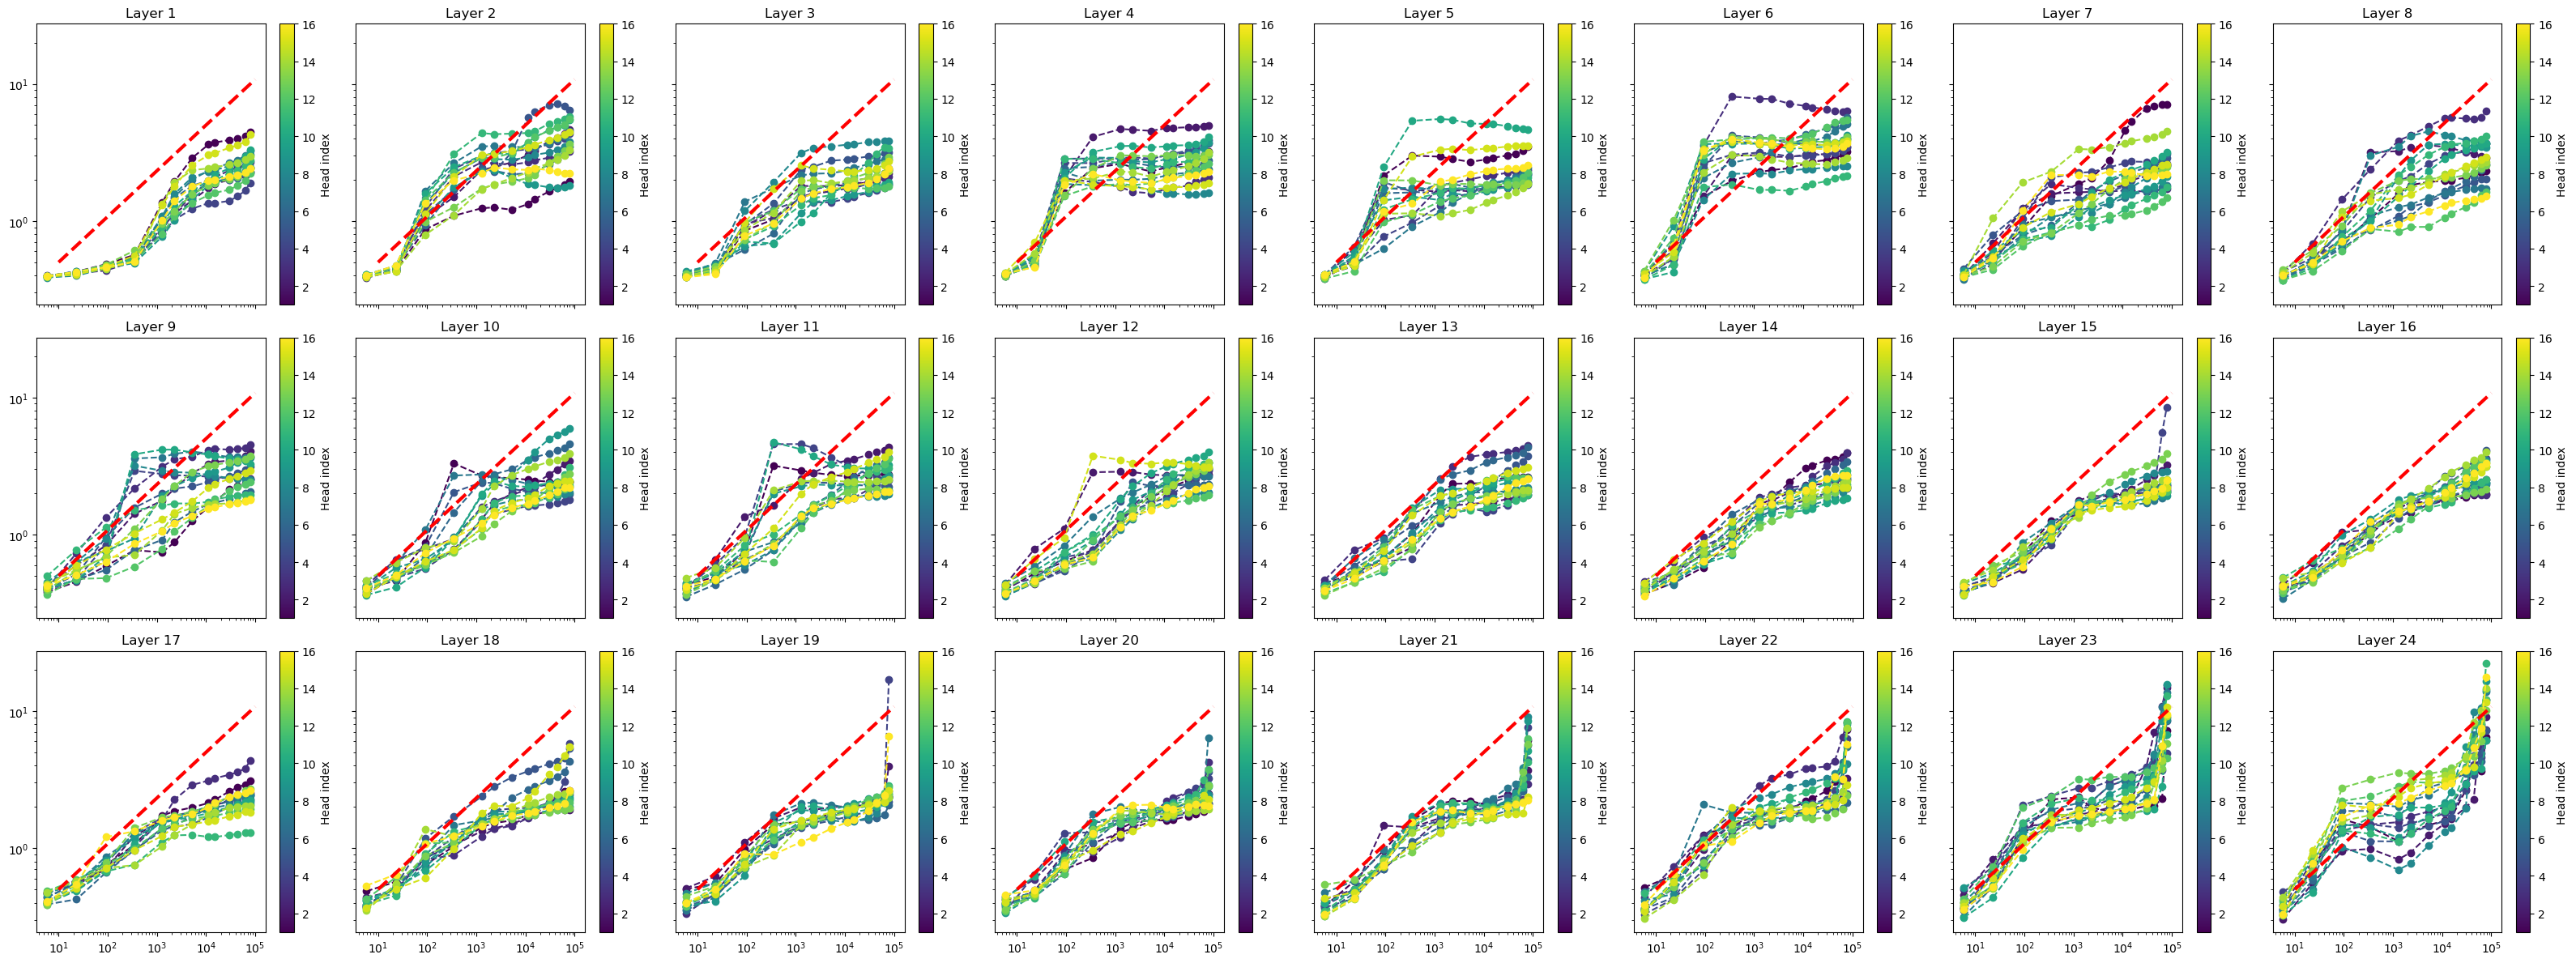

In [3]:
cmap = plt.get_cmap('viridis')
norm = mcolors.Normalize(vmin=1, vmax=num_heads)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
fig, axs = plt.subplots(3, n_layers // 3, figsize=(32, 12), sharex = True, sharey = True)
flat_axs = axs.flatten()
for layer in range(n_layers):
    for head in range(num_heads):
        flat_axs[layer].plot(tau, attn_std[:, layer, head], 'o--', color=cmap(head / (num_heads - 1)))
    flat_axs[layer].plot([1e+1,1e+5], [.5, .5 * 1e+4 ** (1/3)], 'r--', linewidth=3)
    flat_axs[layer].set_xscale('log')
    flat_axs[layer].set_yscale('log')
    flat_axs[layer].set_title(f'Layer {layer+1}')
    fig.colorbar(sm, ax=flat_axs[layer], label='Head index')
plt.tight_layout()

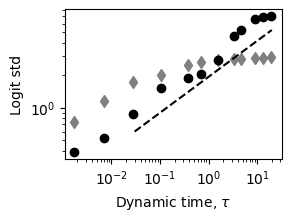

In [49]:
plt.figure(figsize=(2.8, 2.1), constrained_layout=True)
head_logit_std = np.array([0.63249254, 0.6324913 , 0.6325526 , 0.63289446, 0.6337632 ,
       0.6282234 , 0.6229422 , 0.7388862 , 1.1514301 , 1.7127844 ,
       1.9963856 , 2.4947193 , 2.6582873 , 2.767092  , 2.811778  ,
       2.8159978 , 2.8707433 , 2.8898911 , 2.9665735 , 3.052835  ])
plt.plot(tau[:-1] * 3e-4, head_logit_std[7:-1], 'd', color='grey')
plt.plot(tau[:-1] * 3e-4, attn_std[:-1,6,0], 'ko')
#plt.plot(tau * 1.2e-4, attn_std[:,23,5], 'ko')
#plt.plot(tau * 1.2e-4, attn_std[:,23,16], 'ko')
plt.plot([3e-2,2e+1], [.6, .6 * (2e+1/3e-2) ** (1/3)], 'k--')
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'Dynamic time, $\tau$')
plt.ylabel('Logit std')
plt.savefig('../figures/logit_std_410m.pdf')

In [4]:
def H_gaussian(beta, n_samples = 1024):
    logits = np.random.normal(loc=0.0, scale=beta, size=(n_samples,))
    prob = np.exp(logits - np.max(logits))
    prob /= np.sum(prob)
    return -np.sum(prob * np.log(prob + 1e-12))

H_theory = []
for ctx_len in range(2, 2048):
    beta = np.sqrt(2 * np.log(ctx_len))
    H_theory.append(H_gaussian(beta, ctx_len))
H_theory = np.array(H_theory)
H_t_mean = np.mean(H_theory)
H_head = np.array([H_gaussian(np.sqrt(2 * np.log(32000)), 32000) for i in range(500)]).mean()

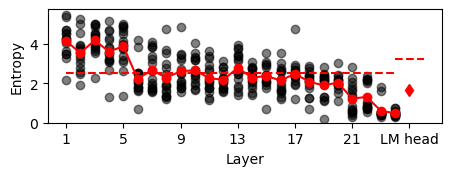

In [9]:
# last point
plt.figure(figsize=(4.4, 1.65), constrained_layout=True)
plt.plot(range(1, n_layers + 1), attn_entropy[-1, :, :], 'o', color='k', alpha = 0.5)
plt.plot(range(1, n_layers + 1), attn_entropy[-1, :, :].mean(axis=1), 'o-', color='r')
plt.plot(range(1, n_layers + 1), H_t_mean * np.ones(n_layers), 'r--')
plt.plot([25], [1.69], 'd', color='r')
plt.plot([24,26], [H_head, H_head], 'r--')
plt.xticks([i for i in range(1, n_layers + 1, 4)]+[25], labels=[str(i) for i in range(1, n_layers + 1, 4)] + ['LM head'])
plt.ylim(0, None)
plt.ylabel(r"Entropy")
plt.xlabel(r"Layer")
plt.savefig('../figures/attn_entropy_410m.png', dpi=300)